In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("Set2")

# ── Load all 4 tables ──────────────────────────────────────


customers    = pd.read_csv(r'/Users/siddharthm/Desktop/churn-prediction/data/processed/telco_cleaned.csv')
transactions = pd.read_csv(r'/Users/siddharthm/Desktop/churn-prediction/data/synthetic/transactions.csv',
                           parse_dates=['transaction_date'])
sessions     = pd.read_csv(r'/Users/siddharthm/Desktop/churn-prediction/data/synthetic/sessions.csv',
                           parse_dates=['session_start'])
tickets      = pd.read_csv(r'/Users/siddharthm/Desktop/churn-prediction/data/synthetic/support_tickets.csv',
                           parse_dates=['created_date', 'resolved_date'])

print("All tables loaded")
print(f"  customers:    {customers.shape}")
print(f"  transactions: {transactions.shape}")
print(f"  sessions:     {sessions.shape}")
print(f"  tickets:      {tickets.shape}")

All tables loaded
  customers:    (7043, 24)
  transactions: (202377, 6)
  sessions:     (1218789, 6)
  tickets:      (41190, 7)


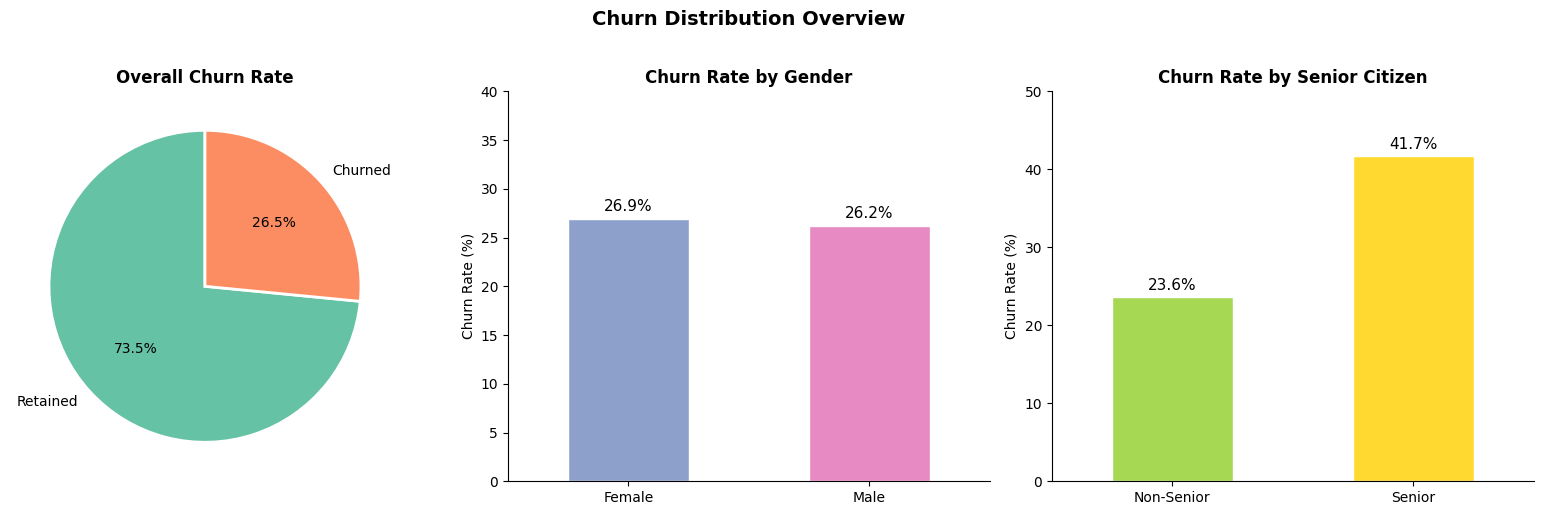


  CHURN SUMMARY
  Total customers:   7,043
  Churned:           1,869  (26.5%)
  Retained:          5,174  (73.5%)
  Senior citizens:   16.2% of customer base
  Gender split:      3,555 Male / 3,488 Female


In [6]:
# ── Cell 2: Churn Distribution Overview ───────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Churn Distribution Overview', fontsize=14, fontweight='bold', y=1.02)

# --- Plot 1: Overall churn pie chart ---
churn_counts = customers['Churn'].value_counts()
axes[0].pie(churn_counts, labels=['Retained', 'Churned'],
            autopct='%1.1f%%', colors=['#66c2a5', '#fc8d62'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Overall Churn Rate', fontweight='bold')

# --- Plot 2: Churn by Gender ---
gender_churn = customers.groupby('gender')['churn_binary'].mean() * 100
gender_churn.plot(kind='bar', ax=axes[1], color=['#8da0cb', '#e78ac3'],
                  edgecolor='white', width=0.5)
axes[1].set_title('Churn Rate by Gender', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 40)
axes[1].tick_params(axis='x', rotation=0)
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=11)

# --- Plot 3: Churn by Senior Citizen ---
senior_map = {0: 'Non-Senior', 1: 'Senior'}
customers['senior_label'] = customers['SeniorCitizen'].map(senior_map)
senior_churn = customers.groupby('senior_label')['churn_binary'].mean() * 100
senior_churn.plot(kind='bar', ax=axes[2], color=['#a6d854', '#ffd92f'],
                  edgecolor='white', width=0.5)
axes[2].set_title('Churn Rate by Senior Citizen', fontweight='bold')
axes[2].set_ylabel('Churn Rate (%)')
axes[2].set_xlabel('')
axes[2].set_ylim(0, 50)
axes[2].tick_params(axis='x', rotation=0)
for bar in axes[2].patches:
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

# --- Summary stats ---
total     = len(customers)
churned   = customers['churn_binary'].sum()
retained  = total - churned
senior_pct = customers['SeniorCitizen'].mean() * 100

print(f"\n{'='*45}")
print(f"  CHURN SUMMARY")
print(f"{'='*45}")
print(f"  Total customers:   {total:,}")
print(f"  Churned:           {churned:,}  ({churned/total*100:.1f}%)")
print(f"  Retained:          {retained:,}  ({retained/total*100:.1f}%)")
print(f"  Senior citizens:   {senior_pct:.1f}% of customer base")
print(f"  Gender split:      {customers['gender'].value_counts()['Male']:,} Male / {customers['gender'].value_counts()['Female']:,} Female")

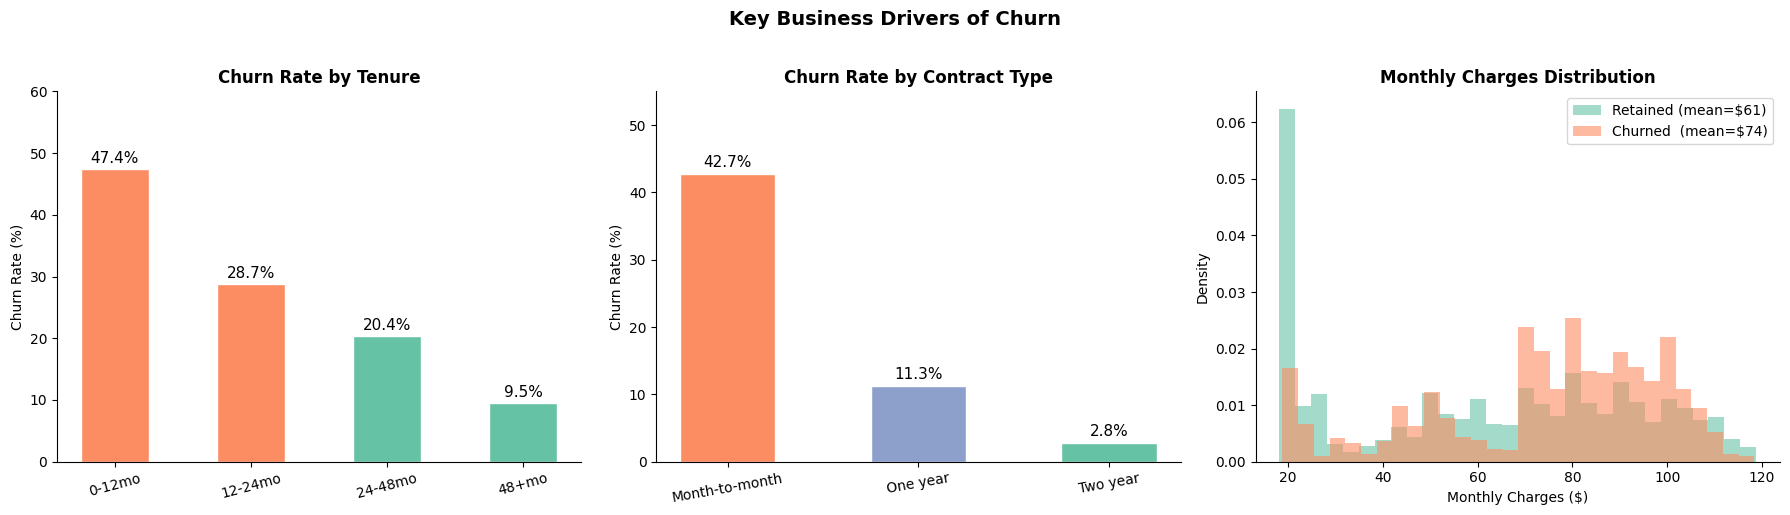


  TENURE & CONTRACT INSIGHTS
  0-12mo              →  47.4% churn  (2,186 customers)
  12-24mo             →  28.7% churn  (1,024 customers)
  24-48mo             →  20.4% churn  (1,594 customers)
  48+mo               →  9.5% churn  (2,239 customers)

  Month-to-month          →  42.7% churn  (3,875 customers)
  One year                →  11.3% churn  (1,473 customers)
  Two year                →  2.8% churn  (1,695 customers)

  Avg monthly charges — Churned:  $74.44
  Avg monthly charges — Retained: $61.27


In [10]:
# ── Cell 3: Churn by Tenure, Contract & Charges ───────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Key Business Drivers of Churn', fontsize=14, fontweight='bold', y=1.02)

# --- Plot 1: Churn rate by tenure group ---
tenure_order = ['0-12mo', '12-24mo', '24-48mo', '48+mo']
tenure_churn = customers.groupby('tenure_group')['churn_binary'].mean() * 100
tenure_churn = tenure_churn.reindex(tenure_order)

bars = axes[0].bar(tenure_order, tenure_churn.values,
                   color=['#fc8d62', '#fc8d62', '#66c2a5', '#66c2a5'],
                   edgecolor='white', width=0.5)
axes[0].set_title('Churn Rate by Tenure', fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, 60)
axes[0].tick_params(axis='x', rotation=15)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 1,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=11)

# --- Plot 2: Churn rate by contract type ---
contract_churn = customers.groupby('Contract')['churn_binary'].mean() * 100
contract_churn = contract_churn.sort_values(ascending=False)

bars2 = axes[1].bar(contract_churn.index, contract_churn.values,
                    color=['#fc8d62', '#8da0cb', '#66c2a5'],
                    edgecolor='white', width=0.5)
axes[1].set_title('Churn Rate by Contract Type', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, 55)
axes[1].tick_params(axis='x', rotation=10)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 1,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=11)

# --- Plot 3: Monthly charges distribution (churned vs retained) ---
churned_charges  = customers[customers['churn_binary'] == 1]['MonthlyCharges']
retained_charges = customers[customers['churn_binary'] == 0]['MonthlyCharges']

axes[2].hist(retained_charges, bins=30, alpha=0.6, color='#66c2a5',
             label=f'Retained (mean=${retained_charges.mean():.0f})', density=True)
axes[2].hist(churned_charges,  bins=30, alpha=0.6, color='#fc8d62',
             label=f'Churned  (mean=${churned_charges.mean():.0f})', density=True)
axes[2].set_title('Monthly Charges Distribution', fontweight='bold')
axes[2].set_xlabel('Monthly Charges ($)')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.show()

# --- Print key stats ---
print(f"\n{'='*50}")
print(f"  TENURE & CONTRACT INSIGHTS")
print(f"{'='*50}")

for group in tenure_order:
    subset = customers[customers['tenure_group'] == group]
    rate = subset['churn_binary'].mean() * 100
    print(f"  {group:<18}  →  {rate:.1f}% churn  ({len(subset):,} customers)")

print()
for contract in contract_churn.index:
    subset = customers[customers['Contract'] == contract]
    rate = subset['churn_binary'].mean() * 100
    print(f"  {contract:<22}  →  {rate:.1f}% churn  ({len(subset):,} customers)")

print(f"\n  Avg monthly charges — Churned:  ${churned_charges.mean():.2f}")
print(f"  Avg monthly charges — Retained: ${retained_charges.mean():.2f}")

In [ ]:
# ── Time-based split using last transaction date ───────────

# Reconstruct days_since_last_txn into the clean feature set
# Higher days_since_last_txn = older transaction = goes into TRAIN
# Lower days_since_last_txn = more recent transaction = goes into TEST

cutoff_percentile = 80   # top 80% oldest transactions → train, bottom 20% → test
cutoff_value = df['days_since_last_txn'].quantile(1 - cutoff_percentile/100)

train_mask = df['days_since_last_txn'] >= cutoff_value
test_mask  = df['days_since_last_txn'] <  cutoff_value

X_tr_t = df.loc[train_mask, feature_cols_clean].values
y_tr_t = df.loc[train_mask, 'is_churn'].values
X_te_t = df.loc[test_mask,  feature_cols_clean].values
y_te_t = df.loc[test_mask,  'is_churn'].values

print(f"Train: {X_tr_t.shape[0]:,} rows — churn rate: {y_tr_t.mean():.2%}")
print(f"Test:  {X_te_t.shape[0]:,} rows  — churn rate: {y_te_t.mean():.2%}")

# Retrain
lgbm_temporal = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.05, num_leaves=31,
    min_child_samples=50, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.5, reg_lambda=0.5, class_weight='balanced',
    random_state=42, n_jobs=-1,
)
lgbm_temporal.fit(
    X_tr_t, y_tr_t,
    eval_set=[(X_te_t, y_te_t)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(period=100)]
)
probs_temporal = lgbm_temporal.predict_proba(X_te_t)[:, 1]
results_temporal = evaluate("LightGBM (temporal split)", y_te_t, probs_temporal)

print(f"\nAUC comparison:")
print(f"  Random split + leaky feature : 0.9950")
print(f"  Random split, no expiry      : 0.9896")
print(f"  Temporal split, no expiry    : {results_temporal['roc_auc']}")

Train: 779,894 rows — churn rate: 10.43%
Test:  191,066 rows  — churn rate: 3.14%
[LightGBM] [Info] Number of positive: 81338, number of negative: 698556
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012989 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4253
[LightGBM] [Info] Number of data points in the train set: 779894, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[100]	valid_0's binary_logloss: 0.43272
[200]	valid_0's binary_logloss: 0.354088
[300]	valid_0's binary_logloss: 0.331144
[400]	valid_0's binary_logloss: 0.316459
[500]	valid_0's binary_logloss: 0.292824
[600]	valid_0's binary_logloss: 0.284409
[700]	valid_0's binary_logloss: 0.279511
[800]	valid_0's binary_logloss: 0.276437
[900]	valid_0's binary_logloss:

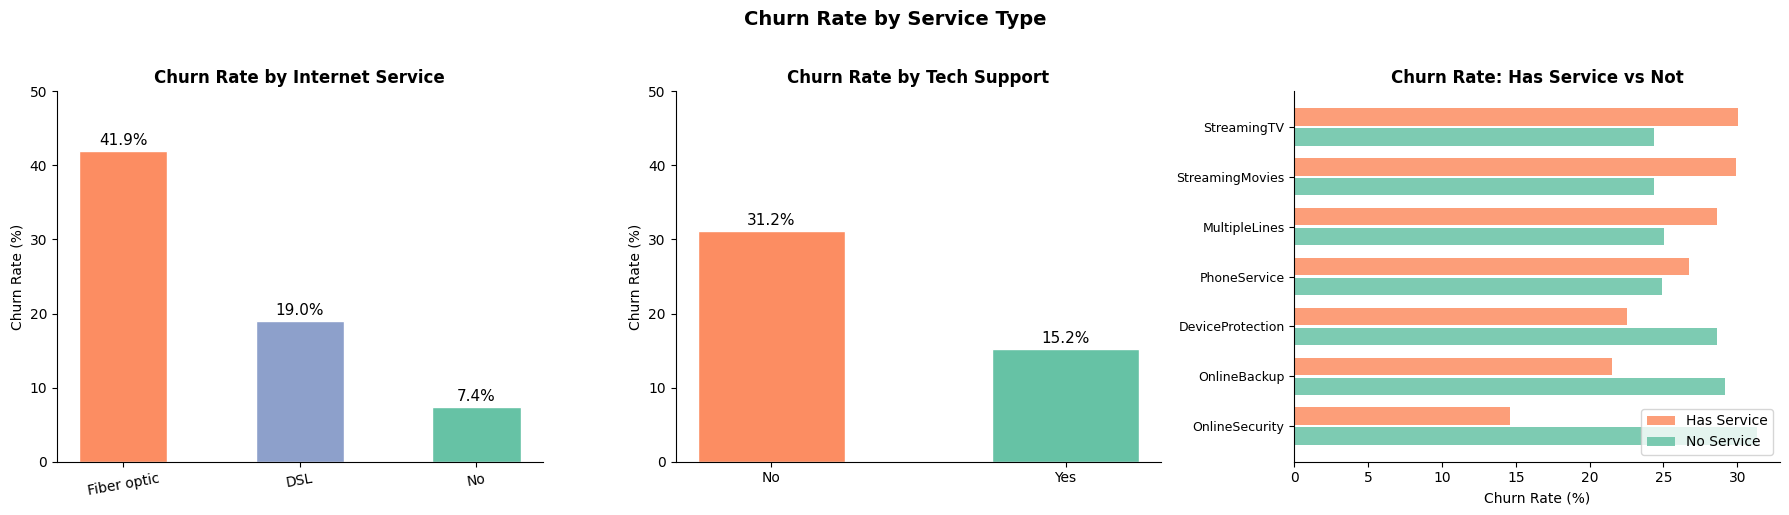


  SERVICE-LEVEL CHURN RATES

  Internet Service:
    Fiber optic      →  41.9%
    DSL              →  19.0%
    No               →  7.4%

  Tech Support:
    No          →  31.2%
    Yes         →  15.2%

  Service features (Has it → churn rate):
    OnlineSecurity         Yes: 14.6%   No: 31.3%
    OnlineBackup           Yes: 21.5%   No: 29.2%
    DeviceProtection       Yes: 22.5%   No: 28.7%
    PhoneService           Yes: 26.7%   No: 24.9%
    MultipleLines          Yes: 28.6%   No: 25.0%
    StreamingMovies        Yes: 29.9%   No: 24.4%
    StreamingTV            Yes: 30.1%   No: 24.3%


In [11]:
# ── Cell 4: Churn by Services ──────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Churn Rate by Service Type', fontsize=14, fontweight='bold', y=1.02)

# --- Plot 1: Churn by Internet Service ---
internet_churn = customers.groupby('InternetService')['churn_binary'].mean() * 100
internet_churn = internet_churn.sort_values(ascending=False)

bars = axes[0].bar(internet_churn.index, internet_churn.values,
                   color=['#fc8d62', '#8da0cb', '#66c2a5'],
                   edgecolor='white', width=0.5)
axes[0].set_title('Churn Rate by Internet Service', fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, 50)
axes[0].tick_params(axis='x', rotation=10)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.8,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=11)

# --- Plot 2: Churn by Tech Support ---
tech_churn = customers.groupby('TechSupport')['churn_binary'].mean() * 100
tech_churn = tech_churn.sort_values(ascending=False)

bars2 = axes[1].bar(tech_churn.index, tech_churn.values,
                    color=['#fc8d62', '#66c2a5'],
                    edgecolor='white', width=0.5)
axes[1].set_title('Churn Rate by Tech Support', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, 50)
axes[1].tick_params(axis='x', rotation=0)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.8,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=11)

# --- Plot 3: Churn rate across all binary service features ---
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'StreamingTV', 'StreamingMovies']

service_churn_rates = {}
for col in service_cols:
    yes_rate = customers[customers[col] == 'Yes']['churn_binary'].mean() * 100
    no_rate  = customers[customers[col] == 'No']['churn_binary'].mean() * 100
    service_churn_rates[col] = {'Yes': yes_rate, 'No': no_rate}

service_df = pd.DataFrame(service_churn_rates).T
service_df = service_df.sort_values('Yes', ascending=True)

y_pos = range(len(service_df))
axes[2].barh([i + 0.2 for i in y_pos], service_df['Yes'],
             height=0.35, color='#fc8d62', label='Has Service', alpha=0.85)
axes[2].barh([i - 0.2 for i in y_pos], service_df['No'],
             height=0.35, color='#66c2a5', label='No Service', alpha=0.85)
axes[2].set_yticks(list(y_pos))
axes[2].set_yticklabels(service_df.index, fontsize=9)
axes[2].set_title('Churn Rate: Has Service vs Not', fontweight='bold')
axes[2].set_xlabel('Churn Rate (%)')
axes[2].legend()

plt.tight_layout()
plt.show()

# --- Print stats ---
print(f"\n{'='*50}")
print(f"  SERVICE-LEVEL CHURN RATES")
print(f"{'='*50}")
print(f"\n  Internet Service:")
for svc, rate in internet_churn.items():
    print(f"    {svc:<15}  →  {rate:.1f}%")

print(f"\n  Tech Support:")
for svc, rate in tech_churn.items():
    print(f"    {svc:<10}  →  {rate:.1f}%")

print(f"\n  Service features (Has it → churn rate):")
for col in service_df.index:
    yes_r = service_df.loc[col, 'Yes']
    no_r  = service_df.loc[col, 'No']
    print(f"    {col:<22} Yes: {yes_r:.1f}%   No: {no_r:.1f}%")

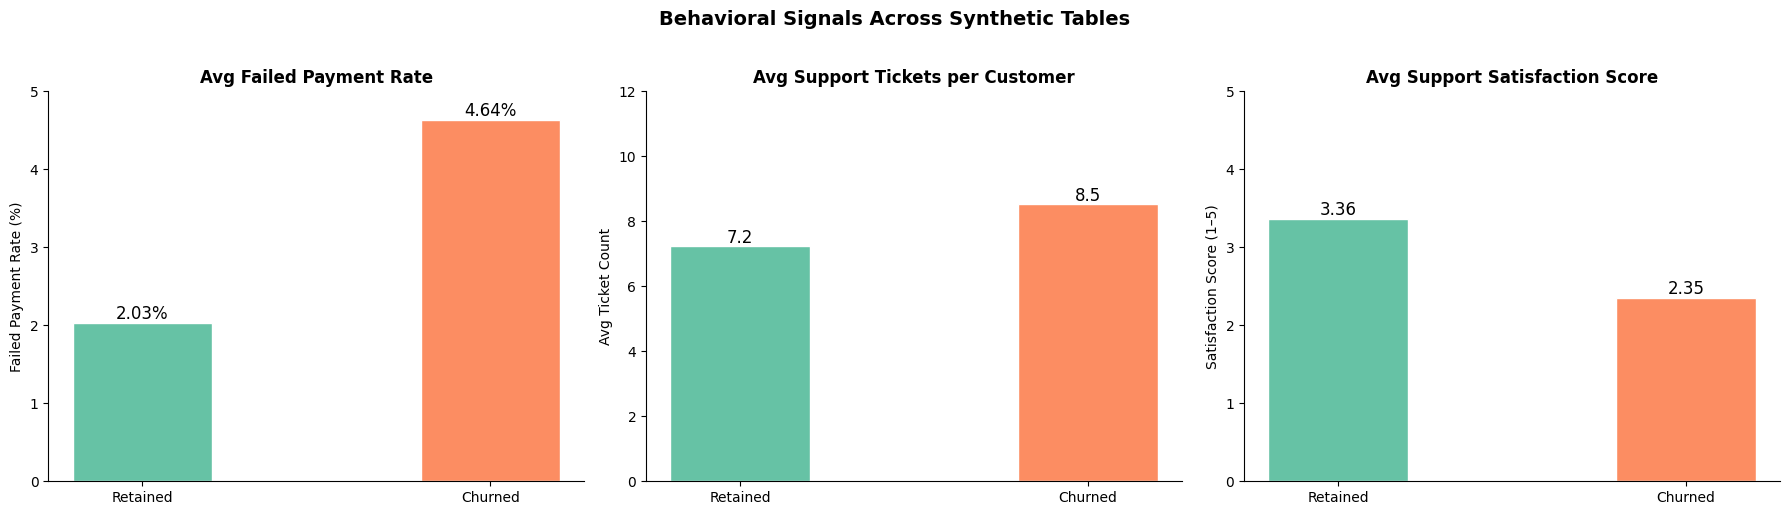


  CROSS-TABLE BEHAVIORAL SIGNALS

  Transactions:
    Failed payment rate  — Churned: 4.64%  Retained: 2.03%
    Avg transactions     — Churned: 23.2  Retained: 37.9

  Sessions:
    Avg session count    — Churned: 180.7  Retained: 286.3
    Avg duration (mins)  — Churned: 32.3  Retained: 29.3

  Support Tickets:
    Avg ticket count     — Churned: 8.5  Retained: 7.2
    Avg satisfaction     — Churned: 2.35  Retained: 3.36


In [12]:
# ── Cell 5: Cross-Table Behavioral Analysis ───────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Behavioral Signals Across Synthetic Tables', fontsize=14, fontweight='bold', y=1.02)

# ── Aggregate each table to customer level ─────────────────

# Transactions: failed payment rate per customer
txn_agg = transactions.groupby('customer_id').agg(
    total_transactions = ('transaction_id', 'count'),
    failed_payments    = ('payment_status', lambda x: (x == 'failed').sum()),
    avg_amount         = ('amount', 'mean')
).reset_index()
txn_agg['failed_payment_rate'] = txn_agg['failed_payments'] / txn_agg['total_transactions']

# Sessions: avg duration per customer
ses_agg = sessions.groupby('customer_id').agg(
    total_sessions    = ('session_id', 'count'),
    avg_duration      = ('duration_minutes', 'mean'),
    avg_pages_viewed  = ('pages_viewed', 'mean')
).reset_index()

# Tickets: count and avg satisfaction per customer
tkt_agg = tickets.groupby('customer_id').agg(
    total_tickets      = ('ticket_id', 'count'),
    avg_satisfaction   = ('satisfaction_score', 'mean')
).reset_index()

# Merge everything onto customers
df = customers[['customerID', 'churn_binary']].copy()
df = df.merge(txn_agg,  left_on='customerID', right_on='customer_id', how='left')
df = df.merge(ses_agg,  left_on='customerID', right_on='customer_id', how='left', suffixes=('', '_ses'))
df = df.merge(tkt_agg,  left_on='customerID', right_on='customer_id', how='left', suffixes=('', '_tkt'))

# Fill customers with no records (zero activity)
df['total_transactions'].fillna(0, inplace=True)
df['failed_payment_rate'].fillna(0, inplace=True)
df['total_sessions'].fillna(0, inplace=True)
df['avg_duration'].fillna(0, inplace=True)
df['total_tickets'].fillna(0, inplace=True)
df['avg_satisfaction'].fillna(3, inplace=True)   # neutral score for no tickets

churned  = df[df['churn_binary'] == 1]
retained = df[df['churn_binary'] == 0]

# --- Plot 1: Failed payment rate ---
axes[0].bar(['Retained', 'Churned'],
            [retained['failed_payment_rate'].mean() * 100,
             churned['failed_payment_rate'].mean() * 100],
            color=['#66c2a5', '#fc8d62'], edgecolor='white', width=0.4)
axes[0].set_title('Avg Failed Payment Rate', fontweight='bold')
axes[0].set_ylabel('Failed Payment Rate (%)')
axes[0].set_ylim(0, 5)
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.05,
                 f'{bar.get_height():.2f}%', ha='center', fontsize=12)

# --- Plot 2: Avg support tickets ---
axes[1].bar(['Retained', 'Churned'],
            [retained['total_tickets'].mean(),
             churned['total_tickets'].mean()],
            color=['#66c2a5', '#fc8d62'], edgecolor='white', width=0.4)
axes[1].set_title('Avg Support Tickets per Customer', fontweight='bold')
axes[1].set_ylabel('Avg Ticket Count')
axes[1].set_ylim(0, 12)
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.1,
                 f'{bar.get_height():.1f}', ha='center', fontsize=12)

# --- Plot 3: Avg satisfaction score ---
axes[2].bar(['Retained', 'Churned'],
            [retained['avg_satisfaction'].mean(),
             churned['avg_satisfaction'].mean()],
            color=['#66c2a5', '#fc8d62'], edgecolor='white', width=0.4)
axes[2].set_title('Avg Support Satisfaction Score', fontweight='bold')
axes[2].set_ylabel('Satisfaction Score (1–5)')
axes[2].set_ylim(0, 5)
for bar in axes[2].patches:
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.05,
                 f'{bar.get_height():.2f}', ha='center', fontsize=12)

plt.tight_layout()
plt.show()

# --- Print summary ---
print(f"\n{'='*55}")
print(f"  CROSS-TABLE BEHAVIORAL SIGNALS")
print(f"{'='*55}")
print(f"\n  Transactions:")
print(f"    Failed payment rate  — Churned: {churned['failed_payment_rate'].mean()*100:.2f}%  "
      f"Retained: {retained['failed_payment_rate'].mean()*100:.2f}%")
print(f"    Avg transactions     — Churned: {churned['total_transactions'].mean():.1f}  "
      f"Retained: {retained['total_transactions'].mean():.1f}")

print(f"\n  Sessions:")
print(f"    Avg session count    — Churned: {churned['total_sessions'].mean():.1f}  "
      f"Retained: {retained['total_sessions'].mean():.1f}")
print(f"    Avg duration (mins)  — Churned: {churned['avg_duration'].mean():.1f}  "
      f"Retained: {retained['avg_duration'].mean():.1f}")

print(f"\n  Support Tickets:")
print(f"    Avg ticket count     — Churned: {churned['total_tickets'].mean():.1f}  "
      f"Retained: {retained['total_tickets'].mean():.1f}")
print(f"    Avg satisfaction     — Churned: {churned['avg_satisfaction'].mean():.2f}  "
      f"Retained: {retained['avg_satisfaction'].mean():.2f}")

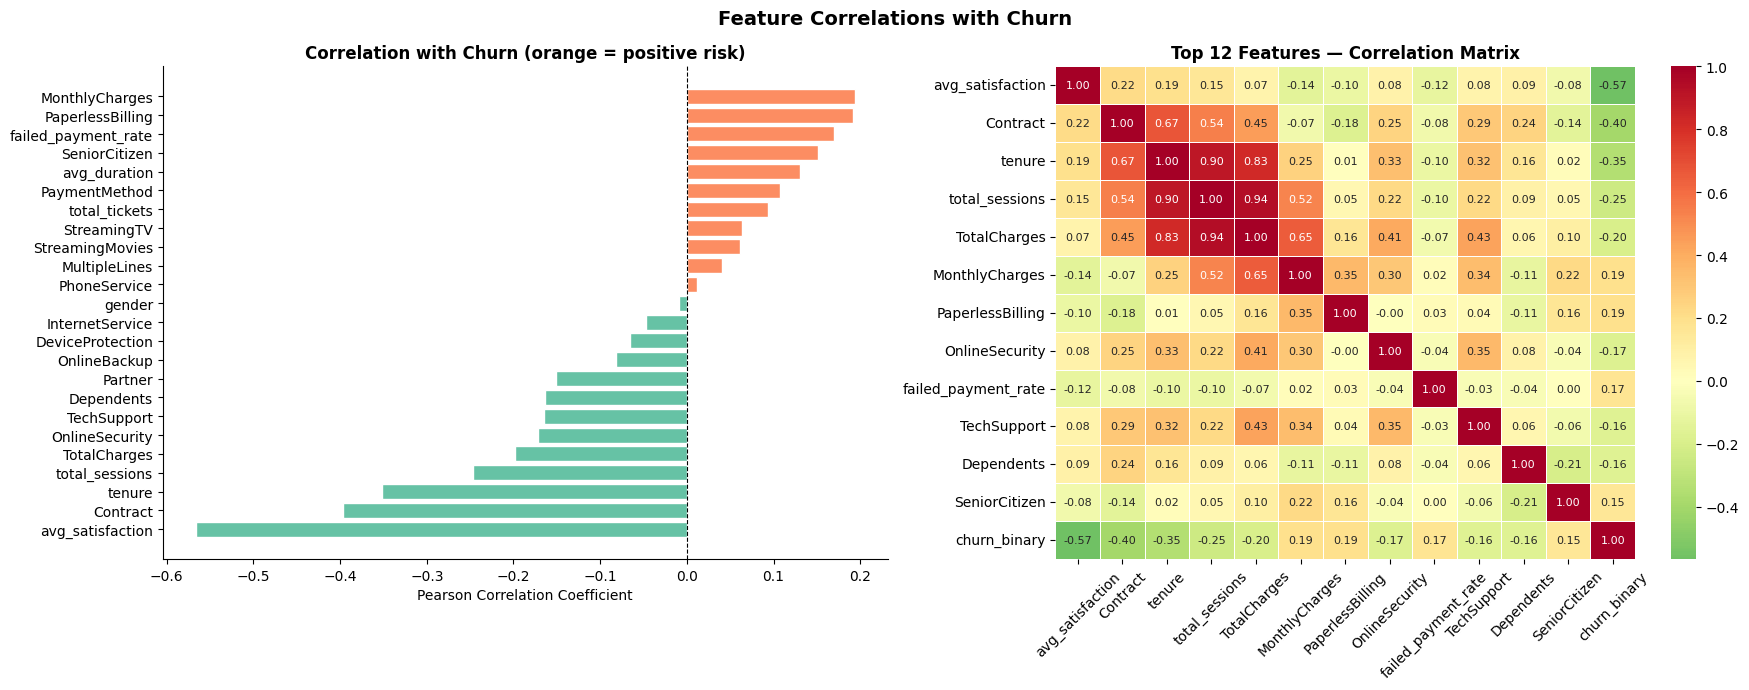


  EDA COMPLETE — TOP PREDICTORS OF CHURN

  Strongest RISK factors (positive correlation):
     MonthlyCharges                  r = +0.193
     PaperlessBilling                r = +0.192
     failed_payment_rate             r = +0.170
     SeniorCitizen                   r = +0.151
     avg_duration                    r = +0.131
     PaymentMethod                   r = +0.107
     total_tickets                   r = +0.094

  Strongest PROTECTIVE factors (negative correlation):
     avg_satisfaction                r = -0.566
     Contract                        r = -0.397
     tenure                          r = -0.352
     total_sessions                  r = -0.247
     TotalCharges                    r = -0.198
     OnlineSecurity                  r = -0.171
     TechSupport                     r = -0.165

  KEY TAKEAWAYS FOR FEATURE ENGINEERING (Phase 3)

  1. Contract type is your #1 predictor — encode as ordinal
     (Month-to-month=2, One year=1, Two year=0)

  2. Tenure is high

In [14]:
# ── Cell 6: Correlation Heatmap + EDA Summary ─────────────

from sklearn.preprocessing import LabelEncoder

df_corr = customers.copy()

# ✅ FIX: Save customerID as string BEFORE encoding loop destroys it
customer_ids = df_corr['customerID'].copy()

# Encode all categorical columns
cat_cols = df_corr.select_dtypes(include='object').columns.tolist()
le = LabelEncoder()
for col in cat_cols:
    df_corr[col] = le.fit_transform(df_corr[col].astype(str))

# ✅ FIX: Restore original string customerID so the merge works
df_corr['customerID'] = customer_ids

# Add behavioral aggregates from Cell 5
df_corr = df_corr.merge(
    df[['customerID', 'failed_payment_rate', 'total_sessions',
        'avg_duration', 'total_tickets', 'avg_satisfaction']],
    on='customerID', how='left'
)

# Select features for heatmap
drop_cols = ['customerID', 'Churn', 'tenure_group', 'charges_quartile',
             'senior_label', 'customer_id']
feature_cols = [c for c in df_corr.columns if c not in drop_cols]

# Compute correlations with churn_binary
corr_with_churn = (df_corr[feature_cols]
                   .corr()['churn_binary']
                   .drop('churn_binary')
                   .sort_values())

# --- Plot 1: Horizontal bar chart of correlations ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Feature Correlations with Churn', fontsize=14, fontweight='bold')

colors = ['#fc8d62' if v > 0 else '#66c2a5' for v in corr_with_churn.values]
axes[0].barh(corr_with_churn.index, corr_with_churn.values,
             color=colors, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Correlation with Churn (orange = positive risk)', fontweight='bold')
axes[0].set_xlabel('Pearson Correlation Coefficient')

# --- Plot 2: Heatmap of top 12 most correlated features ---
top_features = corr_with_churn.abs().sort_values(ascending=False).head(12).index.tolist()
top_features.append('churn_binary')

corr_matrix = df_corr[top_features].corr()

sns.heatmap(corr_matrix, ax=axes[1], annot=True, fmt='.2f',
            cmap='RdYlGn_r', center=0, linewidths=0.5,
            annot_kws={'size': 8})
axes[1].set_title('Top 12 Features — Correlation Matrix', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

# --- Final EDA Summary ---
print(f"\n{'='*60}")
print(f"  EDA COMPLETE — TOP PREDICTORS OF CHURN")
print(f"{'='*60}")

positive = corr_with_churn[corr_with_churn > 0].sort_values(ascending=False)
negative = corr_with_churn[corr_with_churn < 0].sort_values()

print(f"\n  Strongest RISK factors (positive correlation):")
for feat, val in positive.head(7).items():
    print(f"     {feat:<30}  r = {val:+.3f}")

print(f"\n  Strongest PROTECTIVE factors (negative correlation):")
for feat, val in negative.head(7).items():
    print(f"     {feat:<30}  r = {val:+.3f}")

print(f"\n{'='*60}")
print(f"  KEY TAKEAWAYS FOR FEATURE ENGINEERING (Phase 3)")
print(f"{'='*60}")
print("""
  1. Contract type is your #1 predictor — encode as ordinal
     (Month-to-month=2, One year=1, Two year=0)

  2. Tenure is highly protective — use raw value + tenure group

  3. Monthly charges drives risk — keep as-is + add charge bins

  4. Internet service (Fiber optic) is a strong risk flag
     — create a binary: is_fiber_optic

  5. Tech support & Online security are protective
     — create: has_protection_services (count of Yes services)

  6. Avg satisfaction score is your best cross-table feature
     — prioritize it in modeling

  7. Failed payment rate — use directly as a feature
     — also create: has_ever_failed_payment (binary flag)
""")